In [98]:
import numpy as np
import gurobipy as gp
from gurobipy import GRB


def solve_with_obj_band(beta, obj_val, minimize_x1=True):
    """
    Helper LP:
    Given a known optimal objective value obj_val for
        U_beta(x) = b1 * x1 + b2 * x2,
    this LP finds one endpoint of the optimal solution set by
    enforcing U_beta(x) = obj_val and then minimizing / maximizing x1.

    Toy problem:
        minimize   b1 * x1 + b2 * x2
        subject to 0 <= x1 <= 1
                   0 <= x2 <= 1
                   x1 + x2 >= 1

    Here we keep the original feasibility constraints and add:
        b1 * x1 + b2 * x2 = obj_val
    (implemented as two inequalities), then
        min or max x1.
    """
    b1, b2 = float(beta[0]), float(beta[1])

    m = gp.Model("face_endpoint")
    m.Params.OutputFlag = 0
    m.Params.Method = 0  # simplex

    x1 = m.addVar(lb=0.0, ub=1.0, vtype=GRB.CONTINUOUS, name="x1")
    x2 = m.addVar(lb=0.0, ub=1.0, vtype=GRB.CONTINUOUS, name="x2")

    # Original feasibility constraint
    m.addConstr(x1 + x2 >= 1.0, name="c_sum")

    # Enforce staying on the optimal objective hyperplane
    m.addConstr(b1 * x1 + b2 * x2 >= obj_val, name="obj_low")
    m.addConstr(b1 * x1 + b2 * x2 <= obj_val, name="obj_high")

    # Secondary objective: minimize or maximize x1
    if minimize_x1:
        m.setObjective(x1, GRB.MINIMIZE)
    else:
        m.setObjective(x1, GRB.MAXIMIZE)

    m.optimize()

    if m.Status != GRB.OPTIMAL:
        raise RuntimeError(f"Endpoint LP not optimal, status={m.Status}")

    return float(x1.X), float(x2.X)


def solve_multisol_with_points(
    beta,
    n_grid: int = 5,
    rc_tol: float = 1e-8,
):
    beta = np.asarray(beta, dtype=float)
    if beta.shape != (2,):
        raise ValueError("beta must be shape (2,), e.g. np.array([beta1, beta2]).")

    b1, b2 = float(beta[0]), float(beta[1])

    # 1) Solve the primary scalarized LP
    model = gp.Model("multisol")
    model.Params.OutputFlag = 0
    model.Params.Method = 0  # simplex, so VBasis / RC are meaningful

    x1 = model.addVar(lb=0.0, ub=1.0, vtype=GRB.CONTINUOUS, name="x1")
    x2 = model.addVar(lb=0.0, ub=1.0, vtype=GRB.CONTINUOUS, name="x2")

    model.addConstr(x1 + x2 >= 1.0, name="c_sum")

    model.setObjective(b1 * x1 + b2 * x2, GRB.MINIMIZE)
    model.optimize()

    if model.Status != GRB.OPTIMAL:
        return {
            "success": False,
            "status": f"Gurobi status {model.Status}",
            "beta": beta,
        }

    single_opt = {"x1": float(x1.X), "x2": float(x2.X)}
    obj_val = float(model.ObjVal)

    # 2) Detect multiple optimal solutions via reduced costs:
    #    If some nonbasic variable has reduced cost ~ 0, then
    #    there are alternative optima.
    model.update()
    multi_optima = False
    for v in model.getVars():
        # BASIC vs NONBASIC is stored in VBasis
        # For a nonbasic variable, RC = 0 implies alternative optima.
        if v.VBasis != GRB.BASIC and abs(v.RC) <= rc_tol:
            multi_optima = True
            break

    # If no evidence of multiple optima, return single solution
    if not multi_optima:
        return {
            "success": True,
            "status": "optimal (unique solution)",
            "beta": beta,
            "obj_val": obj_val,
            "single_opt": single_opt,
            "multi_optima": False,
            "sol_list": [single_opt]
        }

    # 3) Multiple-optima case: find two extreme optimal points
    x1_min, x2_min = solve_with_obj_band(beta, obj_val, minimize_x1=True)
    x1_max, x2_max = solve_with_obj_band(beta, obj_val, minimize_x1=False)

    # If the two endpoints collapse numerically, treat as single solution
    if abs(x1_min - x1_max) < 1e-8 and abs(x2_min - x2_max) < 1e-8:
        sol = {"x1": x1_min, "x2": x2_min}
        return {
            "success": True,
            "status": "optimal (degenerate multi-solution -> single)",
            "beta": beta,
            "obj_val": obj_val,
            "single_opt": sol,
            "multi_optima": False,
            "sol_list": [sol]
        }

    # 4) Sample n_grid points along the optimal line segment
    sol_list = []
    for k in range(n_grid):
        t = k / (n_grid - 1) if n_grid > 1 else 0.0  # t in [0,1]
        x1_k = (1.0 - t) * x1_min + t * x1_max
        x2_k = (1.0 - t) * x2_min + t * x2_max
        sol_list.append({"x1": float(x1_k), "x2": float(x2_k)})

    return {
        "success": True,
        "status": "optimal (multiple solutions on a line segment)",
        "beta": beta,
        "obj_val": obj_val,
        "single_opt": single_opt,
        "multi_optima": True,
        "sol_list": sol_list
    }


In [159]:
results = []
for beta in [[0.1, 0.9], [0.3, 0.7], [0.5, 0.5], [0.9, 0.1]]:
    res = solve_multisol_with_points(beta, n_grid=100)
    results.append(res)

# print(results)


In [165]:
solve_multisol_with_points([0.5, 0.5], n_grid=100)

{'success': True,
 'status': 'optimal (multiple solutions on a line segment)',
 'beta': array([0.5, 0.5]),
 'obj_val': 0.5,
 'single_opt': {'x1': 1.0, 'x2': 0.0},
 'multi_optima': True,
 'sol_list': [{'x1': 0.0, 'x2': 1.0},
  {'x1': 0.010101010101010102, 'x2': 0.98989898989899},
  {'x1': 0.020202020202020204, 'x2': 0.9797979797979798},
  {'x1': 0.030303030303030304, 'x2': 0.9696969696969697},
  {'x1': 0.04040404040404041, 'x2': 0.9595959595959596},
  {'x1': 0.050505050505050504, 'x2': 0.9494949494949495},
  {'x1': 0.06060606060606061, 'x2': 0.9393939393939394},
  {'x1': 0.0707070707070707, 'x2': 0.9292929292929293},
  {'x1': 0.08080808080808081, 'x2': 0.9191919191919192},
  {'x1': 0.09090909090909091, 'x2': 0.9090909090909091},
  {'x1': 0.10101010101010101, 'x2': 0.898989898989899},
  {'x1': 0.1111111111111111, 'x2': 0.8888888888888888},
  {'x1': 0.12121212121212122, 'x2': 0.8787878787878788},
  {'x1': 0.13131313131313133, 'x2': 0.8686868686868687},
  {'x1': 0.1414141414141414, 'x2': 0

In [160]:
from typing import List, Dict, Any, Optional, Tuple

def aggregate_decision_distribution(
    results: List[Dict[str, Any]],
    beta_weights: Optional[np.ndarray] = None,
    rounding_decimals: int = 8,
) -> List[Dict[str, Any]]:
    M = len(results)
    if M == 0:
        return []

    # If no beta_weights are provided, use uniform weights
    if beta_weights is None:
        beta_weights = np.ones(M, dtype=float) / M
    else:
        beta_weights = np.asarray(beta_weights, dtype=float)
        if beta_weights.shape[0] != M:
            raise ValueError("beta_weights length must match len(results).")
        # Normalize just in case they do not sum to 1
        total = beta_weights.sum()
        if total <= 0:
            raise ValueError("Sum of beta_weights must be positive.")
        beta_weights = beta_weights / total

    # A dictionary to accumulate weights for each unique solution
    # Key: a rounded tuple of (x[var_1], x[var_2], ...), sorted by var name
    # Value: accumulated weight for that solution
    aggregated: Dict[Tuple[float, ...], float] = {}

    # We also store the actual x dict once per unique key
    representative_x: Dict[Tuple[float, ...], Dict[str, float]] = {}

    for j, res in enumerate(results):
        sol_list = res.get("sol_list", [])
        if not sol_list:
            # No solutions for this beta (e.g., infeasible), skip
            continue

        # Number of solutions for this beta
        K_j = len(sol_list)
        # Distribute the beta weight equally among its solutions
        w_each = beta_weights[j] / K_j

        for sol in sol_list:
            # sol is expected to be a dict: { "x1": ..., "x2": ..., ... }
            # Sort variables by name for consistent ordering in the key
            var_names = sorted(sol.keys())
            values = [sol[name] for name in var_names]

            # Round values to avoid tiny numerical differences
            rounded_vals = tuple(
                np.round(v, decimals=rounding_decimals) for v in values
            )

            # Accumulate weight
            if rounded_vals not in aggregated:
                aggregated[rounded_vals] = 0.0
                # Keep original (unrounded) sol as representative
                representative_x[rounded_vals] = {name: float(sol[name]) for name in var_names}

            aggregated[rounded_vals] += w_each

    # Normalize again to ensure total weight ~ 1 (for safety)
    total_weight = sum(aggregated.values())
    if total_weight <= 0:
        return []

    dist: List[Dict[str, Any]] = []
    for key in aggregated:
        w = aggregated[key] / total_weight
        x_dict = representative_x[key]
        dist.append({
            "x": x_dict,
            "weight": float(w),
        })

    dist.sort(key=lambda d: d["weight"], reverse=True)

    return dist


In [161]:
dist = aggregate_decision_distribution(results)
# dist

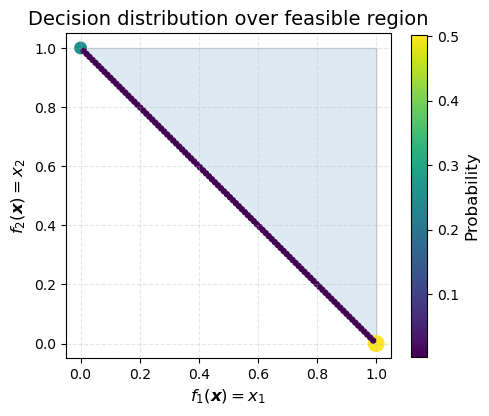

In [181]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection


def plot_decision_distribution(dist):
    x1_vals = np.array([d["x"]["x1"] for d in dist], dtype=float)
    x2_vals = np.array([d["x"]["x2"] for d in dist], dtype=float)
    w_vals  = np.array([d["weight"] for d in dist], dtype=float)
    w_min = w_vals.min()
    w_max = w_vals.max()
    if w_max > w_min:
        w_scaled = 50 + 450 * (w_vals - w_min) / (w_max - w_min)  # marker sizes
    else:
        w_scaled = np.full_like(w_vals, 200.0)
    fig, ax = plt.subplots(figsize=(5, 5))

    # Feasible region is the triangle with vertices:
    # (0,1), (1,0), (1,1)
    triangle = Polygon(
        [(0.0, 1.0), (1.0, 0.0), (1.0, 1.0)],
        closed=True
    )
    patches = [triangle]
    p = PatchCollection(patches, alpha=0.15, edgecolor="k", linewidth=1.0)
    ax.add_collection(p)

    sc = ax.scatter(x1_vals, x2_vals, c=w_vals, cmap="viridis", marker=".", s=w_scaled)

    # Add colorbar to indicate weight
    cbar = fig.colorbar(sc, ax=ax, shrink=0.7)
    cbar.set_label("Probability", fontsize=12)


    ax.set_xlabel(r'$f_1(\boldsymbol{x}) = x_1$', fontsize=12)
    ax.set_ylabel(r"$f_2(\boldsymbol{x}) = x_2$", fontsize=12)
    ax.set_title("Decision distribution over feasible region", fontsize=14)

    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)
    ax.set_aspect("equal", adjustable="box")

    ax.grid(True, linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_decision_distribution(dist)
